In [42]:
import numpy as np
from scipy.fft import dct, idct
import matplotlib.pyplot as plt

In [43]:
f = open("Wildlife.wmv", "rb")

In [44]:
from struct import unpack

fr = f.read(int(np.sqrt(0x100**4 / 100)))
f.close()
l = unpack("<" + "b" * len(fr), fr)
len(fr)

6553

In [45]:
coef = np.round(dct(l, norm="ortho")).astype(np.int64)
threshold = np.sqrt(abs(coef).max())
scoef = np.sort(coef)
coeft = np.array([i if abs(i) > threshold else 0 for i in coef])
reconstructed = np.round(idct(coeft, norm="ortho")).astype(np.int64)
((l != reconstructed)).sum()

np.int64(6325)

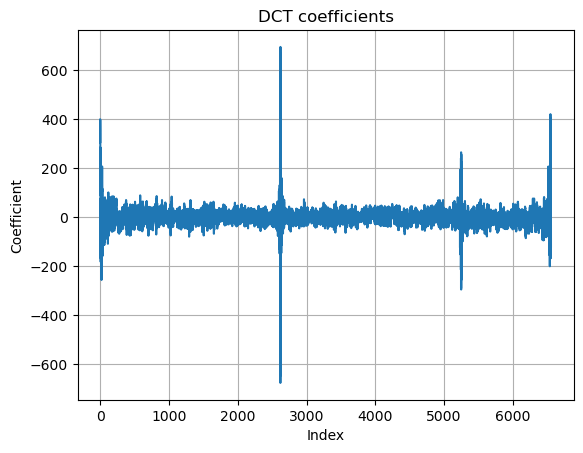

In [46]:
plt.plot(coef)
plt.xlabel("Index")
plt.ylabel("Coefficient")
plt.title("DCT coefficients")
plt.grid(True)
plt.show()

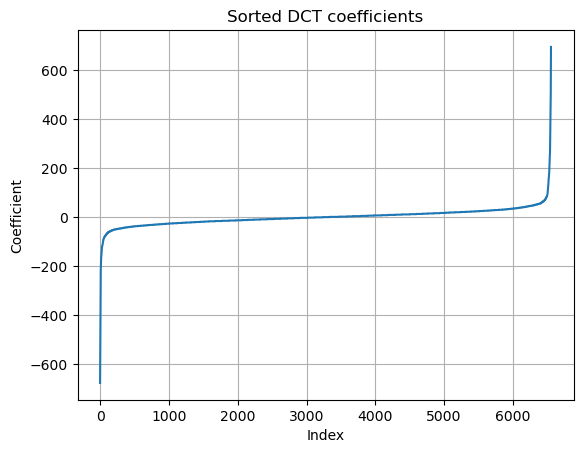

In [47]:
scoef = np.sort(coef)
plt.plot(scoef)
plt.xlabel("Index")
plt.ylabel("Coefficient")
plt.title("Sorted DCT coefficients")
plt.grid(True)
plt.show()

In [48]:
threshold

np.float64(26.38181191654584)

In [49]:
coeftn = coeft - coeft.min()
coeft.min()

np.int64(-678)

In [50]:
energy = coef ** 2
sorted_energy = np.sort(energy)[::-1]
total = energy.sum()

for percent in [1, 5, 10, 25, 50]:
    k = max(1, int(len(coef) * percent / 100))
    ratio = sorted_energy[:k].sum() / total

    print(f"Top {percent:2d}%: {ratio:.2%} energy")

Top  1%: 58.04% energy
Top  5%: 71.45% energy
Top 10%: 78.57% energy
Top 25%: 89.89% energy
Top 50%: 97.46% energy


In [51]:
print(np.sum(np.array(l).astype(float)**2))
print(np.sum(coef**2))

11204990.0
11206356


In [52]:
import heapq

def huffman_bits(data):
    _, counts = np.unique(data, return_counts=True)
    heap = counts.astype(int).tolist()

    if len(heap) <= 1:
        return 0

    heapq.heapify(heap)
    bits = 0

    while len(heap) > 1:
        a = heapq.heappop(heap)
        b = heapq.heappop(heap)
        bits += a + b
        heapq.heappush(heap, a + b)

    return bits


# 원본과 DCT 계수
x = np.asarray(l, dtype=np.int32)
c = np.rint(dct(x, norm="ortho")).astype(np.int32)

# 절댓값이 큰 순서로 정렬한 인덱스
order = np.argsort(np.abs(c))[::-1]

raw_bits = huffman_bits(x)

print("Raw Huffman:", (raw_bits + 7) // 8, "bytes")
print()
print("KEEP% | MODEL(B) | RESID(B) | TOTAL(B) | MAE")

for percent in [0, 1, 5, 10, 25, 50, 75, 100]:

    k = int(len(c) * percent / 100)

    # 가장 큰 k개 계수만 유지
    q = np.zeros_like(c)
    q[order[:k]] = c[order[:k]]

    # 역변환
    predicted = np.rint(
        idct(q.astype(float), norm="ortho")
    ).astype(np.int32)

    # 무손실 복원을 위한 차이
    residual = x - predicted

    # 계수 저장 비용:
    # 위치 2바이트 + 계수 int16 2바이트
    # 또는 위치 비트맵 + 계수 int16 중 작은 것
    nonzero = np.count_nonzero(q)

    model_bytes = min(
        nonzero * 4,
        (len(q) + 7) // 8 + nonzero * 2
    )

    residual_bytes = (huffman_bits(residual) + 7) // 8

    total = model_bytes + residual_bytes
    mae = np.mean(np.abs(residual))

    print(
        f"{percent:5d} | "
        f"{model_bytes:8d} | "
        f"{residual_bytes:8d} | "
        f"{total:8d} | "
        f"{mae:.3f}"
    )

Raw Huffman: 2177 bytes

KEEP% | MODEL(B) | RESID(B) | TOTAL(B) | MAE
    0 |        0 |     2177 |     2177 | 18.110
    1 |      260 |     5017 |     5277 | 14.839
    5 |     1308 |     4990 |     6298 | 13.427
   10 |     2130 |     4966 |     7096 | 12.645
   25 |     4096 |     4691 |     8787 | 9.951
   50 |     7372 |     3925 |    11297 | 5.235
   75 |    10648 |     2675 |    13323 | 1.769
  100 |    13730 |      890 |    14620 | 0.086
